In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

In [3]:
modelo = joblib.load(
    "modelo_clasificacion_conversaciones.joblib"
)

print("Modelo cargado correctamente.")

Modelo cargado correctamente.


In [4]:
df = pd.read_csv("../data/CustomerInteractionData.csv")

X = df["CustomerInteractionRawText"].fillna("")
y = df["AgentAssignedTopic"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de prueba:", len(X_test))

Datos de prueba: 21


prediciones y metricas

In [5]:
predicciones = modelo.predict(X_test)

accuracy = accuracy_score(
    y_test,
    predicciones
)

macro_f1 = f1_score(
    y_test,
    predicciones,
    average="macro"
)

print(f"Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")

Accuracy: 66.67%
Macro F1: 0.6533


analizar confianza

In [6]:
probabilidades = modelo.predict_proba(X_test)

confianzas = probabilidades.max(axis=1)

supervision = pd.DataFrame({
    "Conversación": X_test.values,
    "Real": y_test.values,
    "Predicción": predicciones,
    "Confianza": confianzas
})

supervision["Correcto"] = (
    supervision["Real"] == supervision["Predicción"]
)

supervision.head()

,Conversación,Real,Predicción,Confianza,Correcto
0,All India plans for Data usage. Don't want inc...,Roaming Plans,Data Usage,0.343212,False
1,Added a new line. Offered the customer new plans.,Add New Line,Add New Line,0.395685,True
2,Want to know about offers on recent bill as he...,High Bill,High Bill,0.218165,True
3,Gregory cancelled his services temporarily.,Cancel Service,Cancel Service,0.290176,True
4,#call?,Others,Others,0.134489,True


In [7]:
UMBRAL_CONFIANZA = 0.20

In [8]:
UMBRAL_CONFIANZA = 0.20

baja_confianza = supervision[
    supervision["Confianza"] < UMBRAL_CONFIANZA
]

print(
    f"Predicciones con baja confianza: "
    f"{len(baja_confianza)}"
)

print(
    f"Porcentaje: "
    f"{len(baja_confianza) / len(supervision):.2%}"
)

baja_confianza[
    [
        "Conversación",
        "Real",
        "Predicción",
        "Confianza",
        "Correcto"
    ]
]

Predicciones con baja confianza: 9
Porcentaje: 42.86%


,Conversación,Real,Predicción,Confianza,Correcto
4,#call?,Others,Others,0.134489,True
6,Customer terminated the offers permanently.,Deactivate,Change Plans,0.163059,False
7,935468R911 called to report abrupt disconectio...,Poor Connectivity,Others,0.155017,False
8,Wants to access News channels through phone.,Others,Cancel Service,0.124630,False
9,Kumar called to ask about his porting status. ...,Port Out,Port Out,0.172302,True
10,Faisal wants to add a new business connection ...,Add New Line,Add New Line,0.179849,True
12,called to ask steps for porting out. She is le...,Port Out,Port Out,0.157789,True
17,John Meyer want to cancel the current connection.,Cancel Service,Poor Connectivity,0.127522,False
19,Customer wants to block calls from a particula...,Others,Deactivate,0.126888,False


In [9]:
total_predicciones = len(supervision)

total_correctas = supervision["Correcto"].sum()

total_incorrectas = total_predicciones - total_correctas

porcentaje_error = (
    total_incorrectas / total_predicciones
)

porcentaje_baja_confianza = (
    len(baja_confianza) / total_predicciones
)

print("📊 INDICADORES DE SUPERVISIÓN\n")

print(f"Total de predicciones: {total_predicciones}")

print(f"Predicciones correctas: {total_correctas}")

print(f"Predicciones incorrectas: {total_incorrectas}")

print(f"Tasa de error: {porcentaje_error:.2%}")

print(f"Predicciones de baja confianza: {len(baja_confianza)}")

print(
    f"Porcentaje de baja confianza: "
    f"{porcentaje_baja_confianza:.2%}"
)

📊 INDICADORES DE SUPERVISIÓN

Total de predicciones: 21
Predicciones correctas: 14
Predicciones incorrectas: 7
Tasa de error: 33.33%
Predicciones de baja confianza: 9
Porcentaje de baja confianza: 42.86%


In [10]:
errores_baja_confianza = baja_confianza[
    baja_confianza["Correcto"] == False
]

print(
    "Errores detectados en baja confianza:",
    len(errores_baja_confianza)
)

print(
    "Porcentaje de baja confianza que contiene errores:",
    f"{len(errores_baja_confianza) / len(baja_confianza):.2%}"
)

print(
    "Porcentaje de todos los errores detectados:",
    f"{len(errores_baja_confianza) / total_incorrectas:.2%}"
)

Errores detectados en baja confianza: 5
Porcentaje de baja confianza que contiene errores: 55.56%
Porcentaje de todos los errores detectados: 71.43%


In [11]:
distribucion_real = supervision["Real"].value_counts().sort_index()

distribucion_predicha = supervision["Predicción"].value_counts().sort_index()

comparacion_distribucion = pd.DataFrame({
    "Real": distribucion_real,
    "Predicha": distribucion_predicha
}).fillna(0)

comparacion_distribucion

,Real,Predicha
Add New Line,2,2
Cancel Service,2,2
Change Plans,2,4
Data Usage,2,3
Deactivate,2,1
High Bill,2,2
Others,3,2
Poor Connectivity,2,2
Port Out,2,2
Roaming Plans,2,1


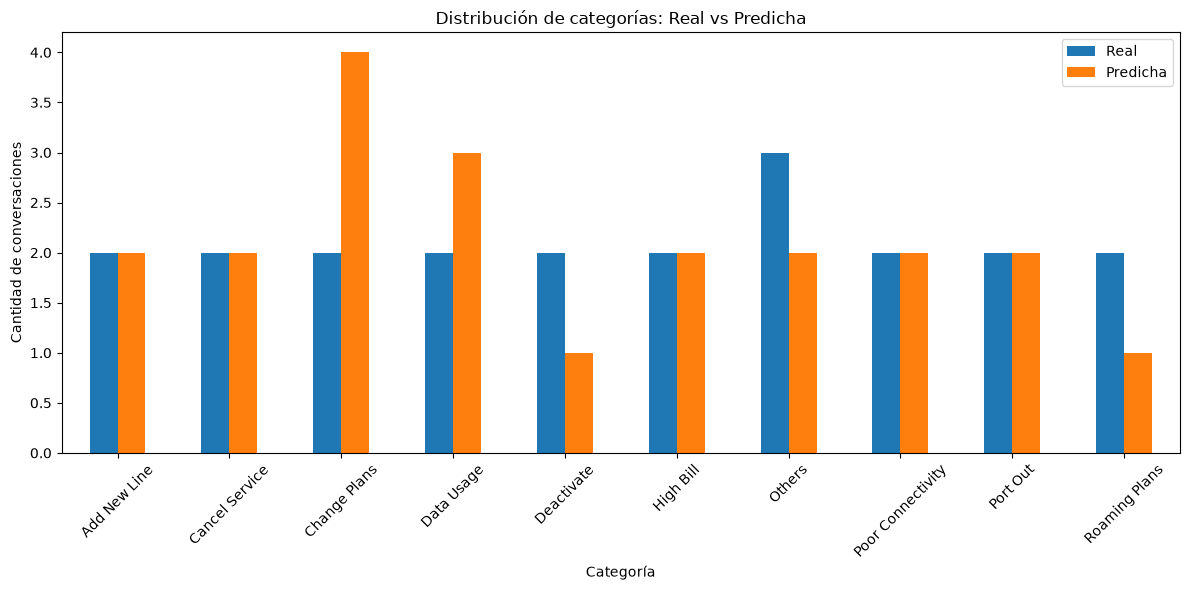

In [12]:
comparacion_distribucion.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Distribución de categorías: Real vs Predicha")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de conversaciones")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [13]:
errores = supervision[
    supervision["Correcto"] == False
]

errores_por_categoria = errores.groupby(
    "Real"
).size().sort_values(ascending=False)

errores_por_categoria

Real
Deactivate           2
Others               2
Cancel Service       1
Poor Connectivity    1
Roaming Plans        1
dtype: int64

In [14]:
matriz_errores = pd.crosstab(
    errores["Real"],
    errores["Predicción"]
)

matriz_errores

Predicción,Cancel Service,Change Plans,Data Usage,Deactivate,Others,Poor Connectivity
Real,,,,,,
Cancel Service,0,0,0,0,0,1
Deactivate,0,2,0,0,0,0
Others,1,0,0,1,0,0
Poor Connectivity,0,0,0,0,1,0
Roaming Plans,0,0,1,0,0,0


reentrenamiento

In [15]:
alertas = []

# Regla 1: rendimiento bajo
if accuracy < 0.60:
    alertas.append(
        "⚠️ Accuracy inferior al 60%. Se recomienda evaluar reentrenamiento."
    )

# Regla 2: demasiadas predicciones de baja confianza
if porcentaje_baja_confianza > 0.50:
    alertas.append(
        "⚠️ Más del 50% de las predicciones tienen baja confianza."
    )

# Regla 3: demasiados errores
if porcentaje_error > 0.40:
    alertas.append(
        "⚠️ La tasa de error supera el 40%."
    )

# Mostrar resultados

if len(alertas) == 0:
    print("✅ El modelo se encuentra dentro de los parámetros definidos.")
else:
    print("🚨 ALERTAS DE SUPERVISIÓN:\n")

    for alerta in alertas:
        print(alerta)

✅ El modelo se encuentra dentro de los parámetros definidos.
